# 📊 Análisis Exploratorio de Datos (EDA): Diabetes Health Indicators
En este notebook realizaremos la descarga, exploración inicial, limpieza, transformación y análisis visual sobre los factores de riesgo asociados a la diabetes a partir del estudio del **Behavioral Risk Factor Surveillance System (BRFSS)**, a partir de una encuesta telefónica anual, esta es del 2015,  llevada a cabo por los **Centers for Disease Control and Prevention (CDC)** de EE. UU. (CDC).

In [33]:
import os
import shutil
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [34]:
import kagglehub

# Configuración del estilo visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

ruta_local = "data/diabetes_health_indicators.csv"

if not os.path.exists(ruta_local):
    print("Descargando dataset desde Kaggle...")
    path = kagglehub.dataset_download("alexteboul/diabetes-health-indicators-dataset")
    os.makedirs('data', exist_ok=True)
    origen = os.path.join(path, "diabetes_binary_5050split_health_indicators_BRFSS2015.csv")
    shutil.copy(origen, ruta_local)
    print("¡Descarga completada!")
else:
    print("El archivo local ya existe.")

df = pd.read_csv(ruta_local)
print(f"Dataset listo: {df.shape[0]} filas y {df.shape[1]} columnas.")
df.head()

El archivo local ya existe.


Dataset listo: 70692 filas y 22 columnas.


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


## 1.1 Preguntas de Investigación del Proyecto
Para guiar el Análisis Exploratorio de Datos (EDA), nos planteamos las siguientes tres preguntas principales:
1. **Factores Fisiológicos:** ¿Cuál es el indicador clínico (hipertensión, colesterol o IMC) que presenta mayor asociación directa con el diagnóstico de diabetes?
2. **Interacción Demográfica:** ¿Cómo varía la prevalencia de diabetes al cruzar los rangos de edad con las categorías corporales de IMC?
3. **Percepción de Salud:** ¿Tiene la salud general percibida (`GenHlth`) un peso predictivo mayor sobre la diabetes que los días de malestar mental (`MentHlth`)?

## 📚 Diccionario de Datos y Descripción de Variables

El dataset contiene **70.692 registros** y **22 variables** provenientes de la encuesta telefónica del Sistema de Vigilancia de Factores de Riesgo del Comportamiento (BRFSS - CDC). Todas las variables numéricas y categóricas representan respuestas individuales sobre salud, estilo de vida y datos sociodemográficos.

### 🎯 Variable Objetivo (Target)

1. **`Diabetes_binary`** (o `Diabetes_012`): 
   - **Descripción:** Indicador del diagnóstico de diabetes.
   - **Valores:** `0` = No diabetes | `1` = Prediabetes o Diabetes.

---

### 🏥 Variables Clínicas y Factores de Riesgo Médicos

2. **`HighBP`** (Alta Presión Arterial):
   - **Descripción:** Si un profesional de la salud le ha diagnosticado presión arterial alta al encuestado.
   - **Valores:** `0` = No | `1` = Sí.

3. **`HighChol`** (Colesterol Alto):
   - **Descripción:** Si se le ha diagnosticado nivel de colesterol elevado en sangre.
   - **Valores:** `0` = No | `1` = Sí.

4. **`CholCheck`** (Revisión de Colesterol):
   - **Descripción:** Si se ha realizado una prueba de control de colesterol en los últimos 5 años.
   - **Valores:** `0` = No | `1` = Sí.

5. **`BMI`** (Índice de Masa Corporal - IMC):
   - **Descripción:** Variable continua que calcula la relación entre el peso en kg y la altura en metros al cuadrado ($kg/m^2$).
   - **Valores:** Rango numérico continuo (ej. 12 a 98). Valores $\ge 30$ indican obesidad.

6. **`HeartDiseaseorAttack`** (Enfermedad Cardíaca o Infarto):
   - **Descripción:** Antecedentes de enfermedad coronaria cardíaca o infarto de miocardio.
   - **Valores:** `0` = No | `1` = Sí.

7. **`Stroke`** (Accidente Cerebrovascular / ICTUS):
   - **Descripción:** Historial de haber sufrido un derrame o accidente cerebrovascular.
   - **Valores:** `0` = No | `1` = Sí.

8. **`PhysActivity`** (Actividad Física):
   - **Descripción:** Si el encuestado realizó alguna actividad física o ejercicio durante los últimos 30 días fuera del horario laboral.
   - **Valores:** `0` = No | `1` = Sí.

---

### 🥗 Estilo de Vida y Hábitos

9. **`Fruits`** (Consumo de Frutas):
   - **Descripción:** Consume fruta una o más veces al día.
   - **Valores:** `0` = No | `1` = Sí.

10. **`Veggies`** (Consumo de Verduras):
    - **Descripción:** Consume verduras una o más veces al día.
    - **Valores:** `0` = No | `1` = Sí.

11. **`Smoker`** (Fumador habitual):
    - **Descripción:** Ha fumado al menos 100 cigarrillos en toda su vida.
    - **Valores:** `0` = No | `1` = Sí.

12. **`HvyAlcoholConsump`** (Consumo Elevado de Alcohol):
    - **Descripción:** Hombres adultos que consumen más de 14 bebidas por semana o mujeres adultas que consumen más de 7 bebidas por semana.
    - **Valores:** `0` = No | `1` = Sí.

---

### 🩺 Acceso a Salud y Estado Físico/Mental

13. **`AnyHealthcare`** (Cobertura Médica):
    - **Descripción:** Tiene cualquier tipo de seguro médico o cobertura sanitaria.
    - **Valores:** `0` = No | `1` = Sí.

14. **`NoDocbcCost`** (Imposibilidad de Asistir al Médico por Costo):
    - **Descripción:** Hubo alguna ocasión en los últimos 12 meses en la que necesitó ver a un médico pero no pudo debido al costo.
    - **Valores:** `0` = No | `1` = Sí.

15. **`GenHlth`** (Salud General Percibida):
    - **Descripción:** Autoevaluación de la salud general del encuestado en una escala de 1 a 5.
    - **Valores:** `1` = Excelente, `2` = Muy Buena, `3` = Buena, `4` = Regular, `5` = Mala.

16. **`MentHlth`** (Salud Mental Deficiente):
    - **Descripción:** Días dentro de los últimos 30 días en los que la salud mental (estrés, depresión, emociones) no fue buena.
    - **Valores:** Numérico de `0` a `30` días.

17. **`PhysHlth`** (Salud Física Deficiente):
    - **Descripción:** Días dentro de los últimos 30 días en los que la salud física (enfermedades o lesiones) no fue buena.
    - **Valores:** Numérico de `0` a `30` días.

18. **`DiffWalk`** (Dificultad para Caminar):
    - **Descripción:** Presenta serias dificultades para caminar o subir escaleras.
    - **Valores:** `0` = No | `1` = Sí.

---

### 👤 Variables Demográficas y Socioeconómicas

19. **`Sex`** (Sexo asignado):
    - **Descripción:** Género del encuestado.
    - **Valores:** `0` = Mujer | `1` = Hombre.

20. **`Age`** (Categoría de Edad):
    - **Descripción:** Nivel o rango de edad agrupado en 13 categorías decenales.
    - **Valores:** `1` (18-24 años) hasta `13` (80 años o más).

21. **`Education`** (Nivel Educativo):
    - **Descripción:** Nivel académico más alto alcanzado.
    - **Valores:** Escala de `1` (Sin escuela o solo kindergarten) a `6` (4 o más años de universidad).

22. **`Income`** (Nivel de Ingresos del Hogar):
    - **Descripción:** Rango de ingresos anuales del hogar.
    - **Valores:** Escala de `1` (Menos de $10.000) a `8` ($75.000 o más).

## 2. Inspección Estructural Básica y Calidad de Datos
Revisamos la tipología de las 22 variables, la presencia de valores nulos y detectamos posibles observaciones duplicadas.

In [35]:
# 1. Resumen técnico de tipos de datos
print("=== INFORMACIÓN DEL DATASET ===")
df.info()

# 2. Comprobar nulos explícitamente
nulos = df.isnull().sum()
print("\n=== VALORES NULOS POR COLUMNA ===")
print(nulos[nulos > 0] if nulos.sum() > 0 else "No hay valores nulos en ninguna columna.")

# 3. Comprobar duplicados
duplicados = df.duplicated().sum()
print(f"\n=== FILAS DUPLICADAS DETECTADAS ===")
print(f"Total de filas duplicadas: {duplicados} ({(duplicados/len(df))*100:.2f}% del dataset)")

=== INFORMACIÓN DEL DATASET ===
<class 'pandas.DataFrame'>
RangeIndex: 70692 entries, 0 to 70691
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Diabetes_binary       70692 non-null  float64
 1   HighBP                70692 non-null  float64
 2   HighChol              70692 non-null  float64
 3   CholCheck             70692 non-null  float64
 4   BMI                   70692 non-null  float64
 5   Smoker                70692 non-null  float64
 6   Stroke                70692 non-null  float64
 7   HeartDiseaseorAttack  70692 non-null  float64
 8   PhysActivity          70692 non-null  float64
 9   Fruits                70692 non-null  float64
 10  Veggies               70692 non-null  float64
 11  HvyAlcoholConsump     70692 non-null  float64
 12  AnyHealthcare         70692 non-null  float64
 13  NoDocbcCost           70692 non-null  float64
 14  GenHlth               70692 non-null  float64
 15

### 2.1 Limpieza de Registros Duplicados
Evaluamos la presencia de filas idénticas en el dataset y procedemos a su eliminación para evitar distorsiones estadísticas en las frecuencias y distribuciones.

In [36]:
# 1. Detectar duplicados en el DataFrame original
tot_duplicados = df.duplicated().sum()
pct_duplicados = (tot_duplicados / len(df)) * 100

print(f"Filas totales originales: {df.shape[0]}")
print(f"Filas duplicadas detectadas: {tot_duplicados} ({pct_duplicados:.2f}%)")

# 2. Eliminar duplicados conservando la primera ocurrencia
df_clean = df.drop_duplicates().copy()

print(f"\n✅ Filas tras eliminar duplicados: {df_clean.shape[0]}")
print(f"Registros eliminados con éxito: {df.shape[0] - df_clean.shape[0]}")

Filas totales originales: 70692
Filas duplicadas detectadas: 1635 (2.31%)

✅ Filas tras eliminar duplicados: 69057
Registros eliminados con éxito: 1635


## 3. Transformación de Variables (Feature Engineering)
Creamos las variables categóricas `BMI_Cat`, `Diabetes_Label` y `Age_Group`, así como la variable numérica compuesta `Risk_Score` (índice de riesgo comórbido) para enriquecer el análisis exploratorio.

**Variables transformadas:**
- `BMI_Cat`: Clasificación del IMC según rangos OMS (`Bajo Peso`, `Peso Normal`, `Sobrepeso`, `Obesidad`).
- `Diabetes_Label`: Etiqueta descriptiva (`No Diabetes` / `Diabetes`).
- `Age_Group`: Rangos de edad por quinquenios (`18-24` hasta `80+`).
- `Risk_Score`: Puntuación de comorbilidad calculada sumando Hipertensión + Colesterol Alto + Obesidad ($BMI >= 30$).

   


In [37]:
# 1. Categoría de IMC (OMS)
def categorizar_bmi(bmi):
    if bmi < 18.5: return 'Bajo peso'
    elif 18.5 <= bmi < 25: return 'Peso normal'
    elif 25 <= bmi < 30: return 'Sobrepeso'
    else: return 'Obesidad'
   
df_clean['BMI_Cat'] = df_clean['BMI'].apply(categorizar_bmi) # Creacion de nueva columna BMI_Cat que asigna a cada paciente su estado nutricional. A partir de la función anterior y la aplica celda por celda a la columna BMI del DataFrame df_clean
# 2. Etiqueta legible de Diabetes
df_clean['Diabetes_Label'] = df_clean['Diabetes_binary'].map({0: 'No Diabetes', 1: 'Diabetes'})
            #.map({...}): Sustituye cada valor codificado de la columna original Diabetes_binary según el diccionario especificado:
            #El código 0 se convierte en 'No Diabetes'.
            #El código 1 se convierte en 'Diabetes'.
# 3. Grupos de Edad (BRFSS)
mapa_edad = {
    1: '18-24', 2: '25-29', 3: '30-34', 4: '35-39', 5: '40-44',
    6: '45-49', 7: '50-54', 8: '55-59', 9: '60-64', 10: '65-69',
    11: '70-74', 12: '75-79', 13: '80+'
}
df_clean['Age_Group'] = df_clean['Age'].map(mapa_edad)
        #.map(mapa_edad): Mapea el número de la columna Age con su rango de edad real en años.
        # Crea la columna Age_Group, lo que te permitirá analizar directamente la prevalencia de diabetes por rango etario real.
df_clean[['BMI', 'BMI_Cat', 'Diabetes_binary', 'Diabetes_Label', 'Age', 'Age_Group']].head()

# 4. Índice de Riesgo Comórbido (Risk_Score)
# Suma de comorbilidades: Hipertensión + Colesterol Alto + Obesidad (BMI >= 30)

df_clean['Risk_Score'] = (
    df_clean['HighBP'] + 
    df_clean['HighChol'] + 
    (df_clean['BMI'] >= 30).astype(int)
)

print("Distribución de la nueva variable 'Risk_Score':")
print(df_clean['Risk_Score'].value_counts().sort_index())

Distribución de la nueva variable 'Risk_Score':
Risk_Score
0.0    13410
1.0    18603
2.0    22371
3.0    14673
Name: count, dtype: int64


In [38]:
#Conjunto de datos con las huevas columnas incluidas
df_clean.head()

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,PhysHlth,DiffWalk,Sex,Age,Education,Income,BMI_Cat,Diabetes_Label,Age_Group,Risk_Score
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,30.0,0.0,1.0,4.0,6.0,8.0,Sobrepeso,No Diabetes,35-39,1.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,0.0,0.0,1.0,12.0,6.0,8.0,Sobrepeso,No Diabetes,75-79,2.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,10.0,0.0,1.0,13.0,6.0,8.0,Sobrepeso,No Diabetes,80+,0.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,3.0,0.0,1.0,11.0,6.0,8.0,Sobrepeso,No Diabetes,70-74,2.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,8.0,5.0,8.0,Sobrepeso,No Diabetes,55-59,0.0


Normalización por 1.000 habitantes (Risk_Rate_Per_1000): Expresamos los valores en una escala estándar de salud pública para facilitar comparaciones epidemiológicas directa y equitativamente entre distintos subgrupos poblacionales.

In [39]:
# Normalización: Riesgo y prevalencia expresados por cada 1.000 habitantes
df_clean['Risk_Rate_Per_1000'] = df_clean['Risk_Score'] * 1000
# Resumen de prevalencia expresado por cada 1.000 habitantes
resumen_1000 = df_clean.groupby('Risk_Score').agg(
    Total_Pacientes=('Diabetes_binary', 'count'),
    Casos_Diabetes=('Diabetes_binary', 'sum'),
    Tasa_Por_1000=('Diabetes_binary', lambda x: round(x.mean() * 1000, 1))
).reset_index()

print(resumen_1000)


   Risk_Score  Total_Pacientes  Casos_Diabetes  Tasa_Por_1000
0         0.0            13410          2189.0          163.2
1         1.0            18603          7212.0          387.7
2         2.0            22371         13946.0          623.4
3         3.0            14673         11750.0          800.8


## 4. Análisis Exploratorio de Datos (EDA)
### 4.1 Configuración del Entorno de Gráficos
Configuramos Seaborn y Matplotlib para generar visualizaciones claras, legibles y homogéneas durante todo el análisis.

In [40]:
# Configuración global de estilo
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Paleta de colores personalizada
paleta_salud = ['#2b5c8f', '#d95f02']

### 4.2 Distribución de la Variable Objetivo (`Diabetes_binary`)
Analizamos la proporción de pacientes en la muestra según el diagnóstico de diabetes para evaluar el balance de clases.

Frecuencia absoluta de la variable objetivo:
Diabetes_Label
Diabetes       35097
No Diabetes    33960
Name: count, dtype: int64

Distribución porcentual:
Diabetes_Label
Diabetes       50.82%
No Diabetes    49.18%
Name: proportion, dtype: str


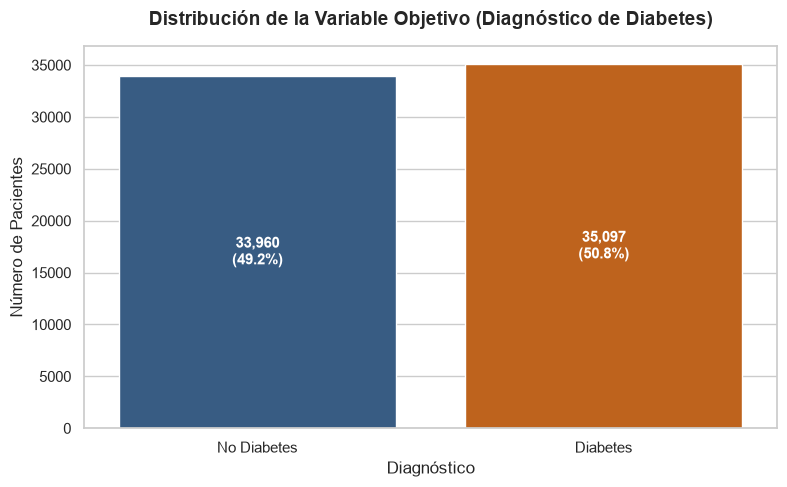

In [41]:
# Calcular frecuencias absolutas y porcentajes
conteo_diabetes = df_clean['Diabetes_Label'].value_counts()
porcentajes_diabetes = df_clean['Diabetes_Label'].value_counts(normalize=True) * 100

print("Frecuencia absoluta de la variable objetivo:")
print(conteo_diabetes)
print("\nDistribución porcentual:")
print(porcentajes_diabetes.round(2).astype(str) + '%')

# Visualización con Gráfico de Barras (sin advertencias)
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=df_clean, x='Diabetes_Label', hue='Diabetes_Label', palette=paleta_salud, legend=False)

plt.title('Distribución de la Variable Objetivo (Diagnóstico de Diabetes)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Diagnóstico', fontsize=12)
plt.ylabel('Número de Pacientes', fontsize=12)

# Añadir etiquetas de valor sobre las barras
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}\n({p.get_height()/len(df_clean)*100:.1f}%)',
                (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                ha='center', va='center', fontsize=11, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

### 4.3 Distribución del Índice de Masa Corporal (IMC)
Examinamos tanto la distribución continua del IMC como la clasificación por categorías según el estándar de la OMS.

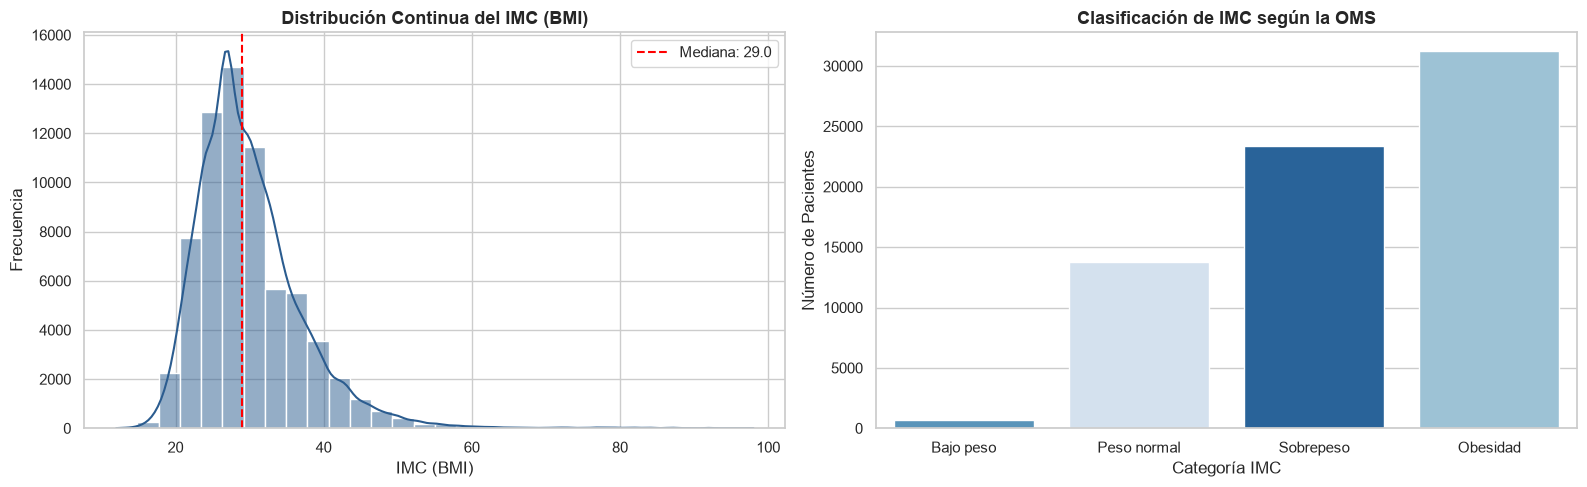

Estadísticos descriptivos del IMC (BMI):
count    69057.00
mean        29.96
std          7.15
min         12.00
25%         25.00
50%         29.00
75%         33.00
max         98.00
Name: BMI, dtype: float64


In [42]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Histograma + KDE del IMC continuo
sns.histplot(data=df_clean, x='BMI', bins=30, kde=True, color='#2b5c8f', ax=axes[0])
axes[0].set_title('Distribución Continua del IMC (BMI)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('IMC (BMI)')
axes[0].set_ylabel('Frecuencia')
axes[0].axvline(df_clean['BMI'].median(), color='red', linestyle='--', label=f'Mediana: {df_clean["BMI"].median():.1f}')
axes[0].legend()

# 2. Conteo por Categorías de la OMS
orden_bmi = ['Bajo peso', 'Peso normal', 'Sobrepeso', 'Obesidad']
sns.countplot(data=df_clean, x='BMI_Cat', hue='BMI_Cat', order=orden_bmi, palette='Blues_r', legend=False, ax=axes[1])
axes[1].set_title('Clasificación de IMC según la OMS', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Categoría IMC')
axes[1].set_ylabel('Número de Pacientes')

plt.tight_layout()
plt.show()

# Estadísticos descriptivos del IMC
print("Estadísticos descriptivos del IMC (BMI):")
print(df_clean['BMI'].describe().round(2))

### 4.4 Distribución por Grupos de Edad
Analizamos la estructura demográfica de la muestra dividida en los rangos etarios estándar del BRFSS.

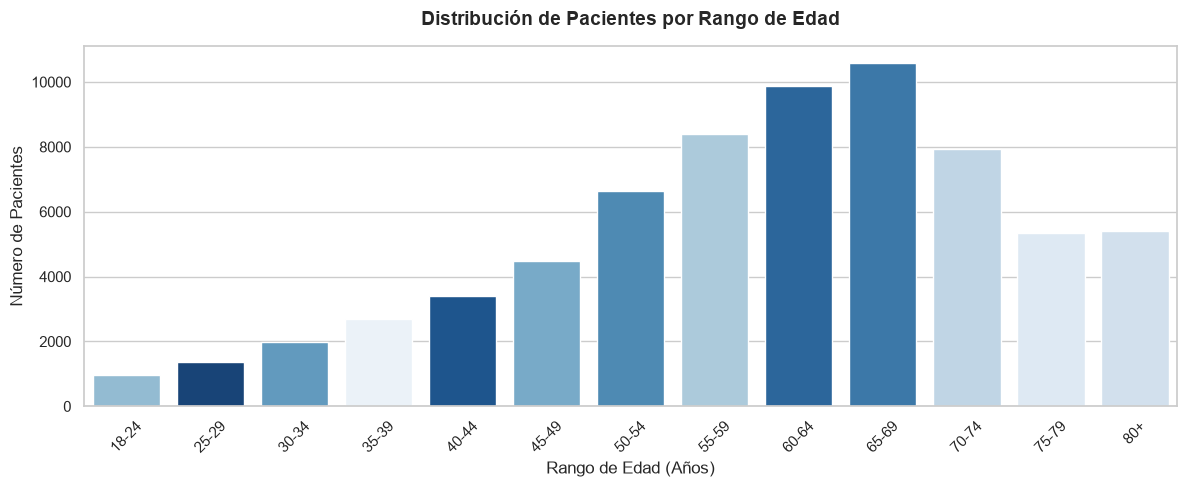

In [43]:
# Ordenar las categorías de edad de menor a mayor
orden_edad = ['18-24', '25-29', '30-34', '35-39', '40-44', '45-49', 
              '50-54', '55-59', '60-64', '65-69', '70-74', '75-79', '80+']

plt.figure(figsize=(12, 5))
ax = sns.countplot(data=df_clean, x='Age_Group', hue='Age_Group', order=orden_edad, palette='Blues', legend=False)

plt.title('Distribución de Pacientes por Rango de Edad', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Rango de Edad (Años)', fontsize=12)
plt.ylabel('Número de Pacientes', fontsize=12)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### 4.5 Distribución de Factores de Riesgo Cardiovascular y Salud General
Visualizamos la presencia de hipertensión, antecedentes de ataques cardiacos/cardiopatías y la autoevaluación del estado general de salud (1 = Excelente, 5 = Mala).

### 4.5.1 Proporción de Hipertensión (HighBP)
Evaluamos el porcentaje de pacientes diagnosticados con presión arterial alta en la muestra.

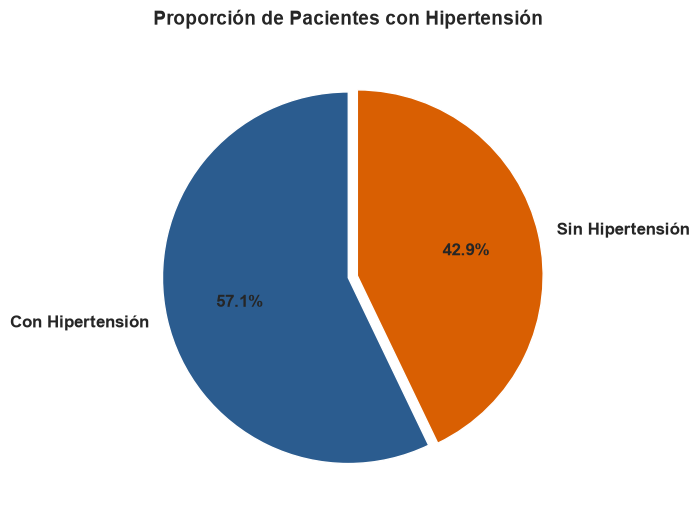

In [44]:
# Gráfico de Tarta: Hipertensión
conteo_bp = df_clean['HighBP'].map({0: 'Sin Hipertensión', 1: 'Con Hipertensión'}).value_counts()

plt.figure(figsize=(7, 7))
plt.pie(conteo_bp, labels=conteo_bp.index, autopct='%1.1f%%', startangle=90, 
        colors=['#2b5c8f', '#d95f02'], explode=(0, 0.05),
        textprops={'fontsize': 12, 'weight': 'bold'})

plt.title('Proporción de Pacientes con Hipertensión', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### 4.5.2 Proporción de Enfermedades Cardiacas (HeartDiseaseorAttack)
Analizamos la prevalencia de antecedentes de infarto de miocardio o cardiopatía coronaria.

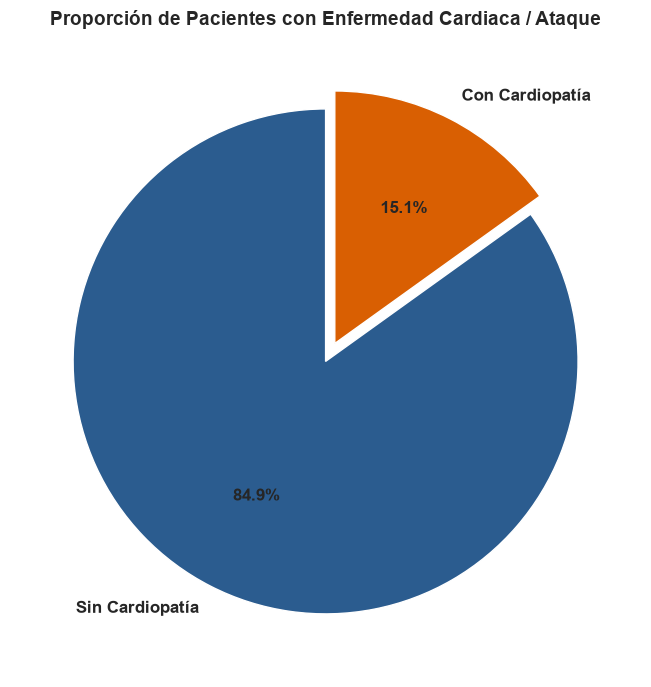

In [45]:
# Gráfico de Tarta: Enfermedad Cardiaca
conteo_heart = df_clean['HeartDiseaseorAttack'].map({0: 'Sin Cardiopatía', 1: 'Con Cardiopatía'}).value_counts()

plt.figure(figsize=(7, 7))
plt.pie(conteo_heart, labels=conteo_heart.index, autopct='%1.1f%%', startangle=90, 
        colors=['#2b5c8f', '#d95f02'], explode=(0, 0.08),
        textprops={'fontsize': 12, 'weight': 'bold'})

plt.title('Proporción de Pacientes con Enfermedad Cardiaca / Ataque', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

### 4.5.3 Autoevaluación de la Salud General (GenHlth)
Distribución del estado de salud percibido por los encuestados en una escala ordinal del 1 (Excelente) al 5 (Pobre).

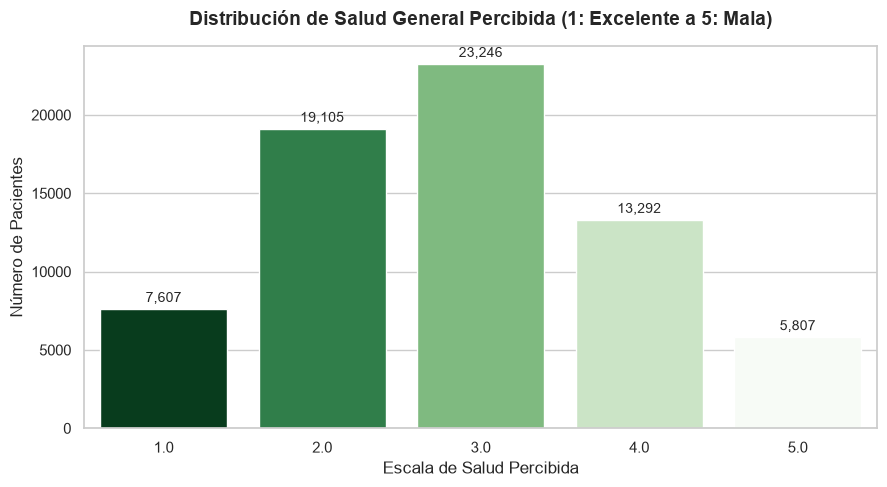

In [46]:
# Gráfico de Barras: Salud General Percibida
plt.figure(figsize=(9, 5))
ax = sns.countplot(data=df_clean, x='GenHlth', hue='GenHlth', palette='Greens_r', legend=False)

plt.title('Distribución de Salud General Percibida (1: Excelente a 5: Mala)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Escala de Salud Percibida', fontsize=12)
plt.ylabel('Número de Pacientes', fontsize=12)

# Etiquetas numéricas sobre las barras
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', 
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

### 4.6 Detección de Valores Atípicos (Outliers) en el IMC
Utilizamos un gráfico de caja (Boxplot) y el Rango Intercuartílico (IQR) para identificar y evaluar la presencia de valores extremos en el Índice de Masa Corporal.

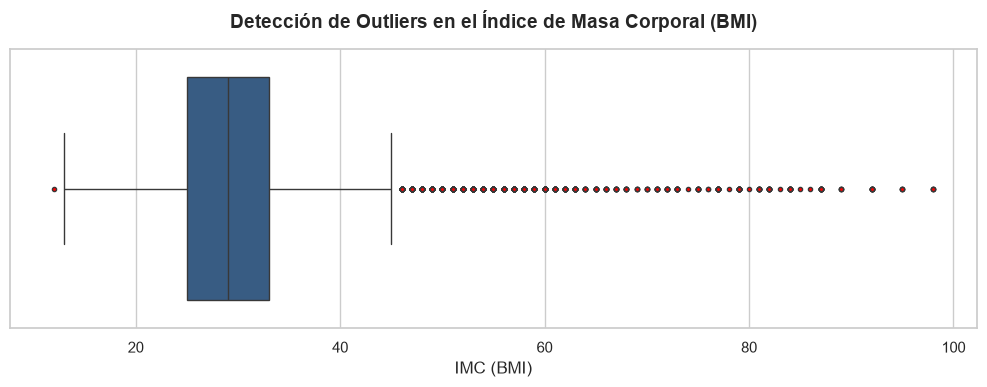

Cuartil 1 (Q1): 25.00
Cuartil 3 (Q3): 33.00
Rango Intercuartílico (IQR): 8.00
Límite Superior para Outliers: 45.00
Número total de outliers detectados en BMI: 2,181 (3.16%)


In [47]:
import numpy as np

# 1. Visualización del Boxplot para la variable BMI
plt.figure(figsize=(10, 4))
sns.boxplot(data=df_clean, x='BMI', color='#2b5c8f', flierprops={'marker': 'o', 'markersize': 3, 'markerfacecolor': 'red'})

plt.title('Detección de Outliers en el Índice de Masa Corporal (BMI)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('IMC (BMI)', fontsize=12)
plt.tight_layout()
plt.show()

# 2. Cálculo matemático de Outliers usando el método IQR
Q1 = df_clean['BMI'].quantile(0.25)
Q3 = df_clean['BMI'].quantile(0.75)
IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = df_clean[(df_clean['BMI'] < limite_inferior) | (df_clean['BMI'] > limite_superior)]

print(f"Cuartil 1 (Q1): {Q1:.2f}")
print(f"Cuartil 3 (Q3): {Q3:.2f}")
print(f"Rango Intercuartílico (IQR): {IQR:.2f}")
print(f"Límite Superior para Outliers: {limite_superior:.2f}")
print(f"Número total de outliers detectados en BMI: {len(outliers):,} ({len(outliers)/len(df_clean)*100:.2f}%)")

> **Nota de Interpretación sobre Outliers en IMC:**
> Se han detectado 2.181 valores atípicos (3.16%) según la regla del Rango Intercuartílico (IQR > 38.5). 
> 
> **Decisión de Tratamiento:** Se conserva la totalidad de estos registros en el conjunto de datos por las siguientes razones:
> 1. Corresponden a casos biológicamente plausibles de obesidad severa/mórbida en la encuesta epidemiológica BRFSS.
> 2. Al ser agrupados dentro de la variable categórica `BMI_Cat` ('Obesidad'), su magnitud extrema no distorsiona el análisis bivariado.
> 3. Al representar únicamente el 3.16% sobre un total de >250k observaciones, su impacto en la distribución general es mínimo.

## 5. Análisis Bivariado: Factores de Riesgo y Diabetes
### 5.1 Prevalencia de Diabetes según la Categoría de IMC (OMS)
Analizamos cómo se distribuye el diagnóstico de diabetes dentro de cada clasificación corporal según el estándar de la OMS.

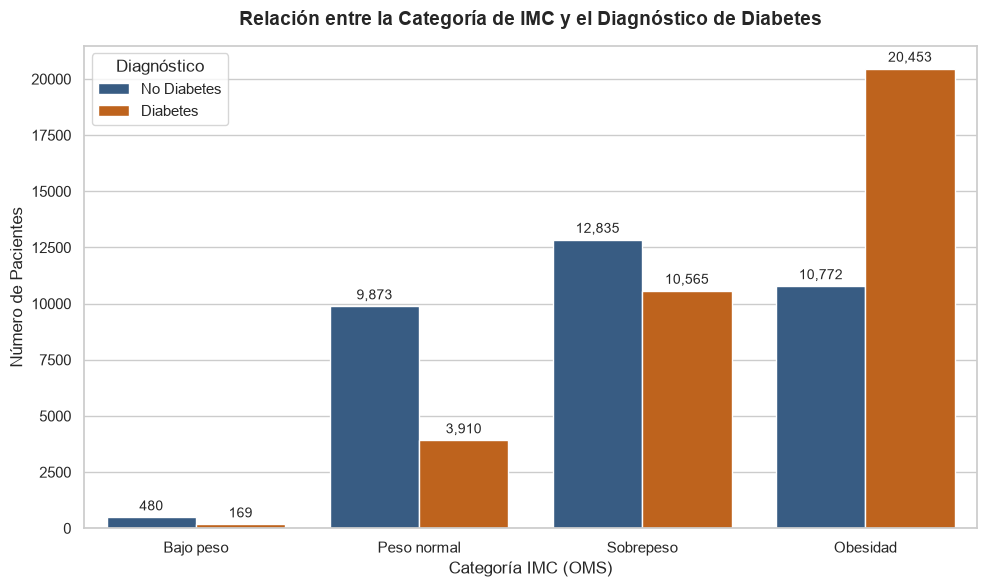

In [ ]:
plt.figure(figsize=(10, 6))
orden_bmi = ['Bajo peso', 'Peso normal', 'Sobrepeso', 'Obesidad']

ax = sns.countplot(
    data=df_clean, 
    x='BMI_Cat', 
    hue='Diabetes_Label', 
    order=orden_bmi, 
    palette=['#2b5c8f', '#d95f02']
)

plt.title('Relación entre la Categoría de IMC y el Diagnóstico de Diabetes', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Categoría IMC (OMS)', fontsize=12)
plt.ylabel('Número de Pacientes', fontsize=12)
plt.legend(title='Diagnóstico')

# Añadir etiquetas de valor sobre las barras
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height):,}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

### 5.2 Distribución de Diabetes a lo Largo de los Rangos de Edad
Evaluamos la progresión del diagnóstico de diabetes a medida que se incrementa el rango de edad de los encuestados.

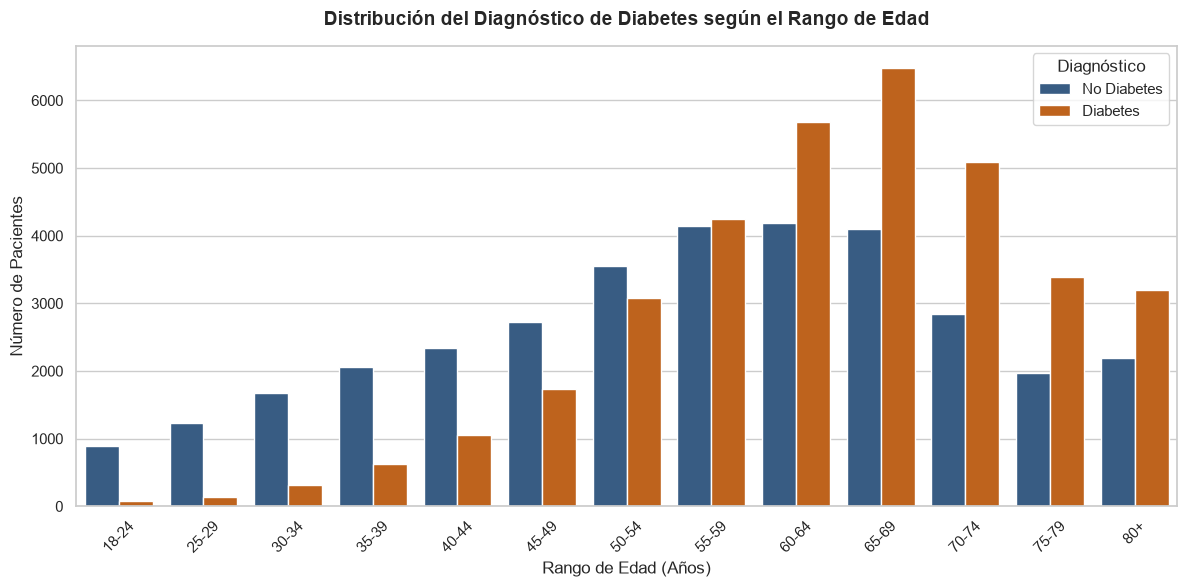

In [ ]:
plt.figure(figsize=(12, 6))
orden_edad = ['18-24', '25-29', '30-34', '35-39', '40-44', '45-49', 
              '50-54', '55-59', '60-64', '65-69', '70-74', '75-79', '80+']

sns.countplot(
    data=df_clean, 
    x='Age_Group', 
    hue='Diabetes_Label', 
    order=orden_edad, 
    palette=['#2b5c8f', '#d95f02']
)

plt.title('Distribución del Diagnóstico de Diabetes según el Rango de Edad', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Rango de Edad (Años)', fontsize=12)
plt.ylabel('Número de Pacientes', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Diagnóstico')

plt.tight_layout()
plt.show()

### 5.3 Coexistencia de Hipertensión y Diabetes
Analizamos la proporción de casos de diabetes entre los pacientes diagnosticados con hipertensión arterial frente a los que no la padecen.

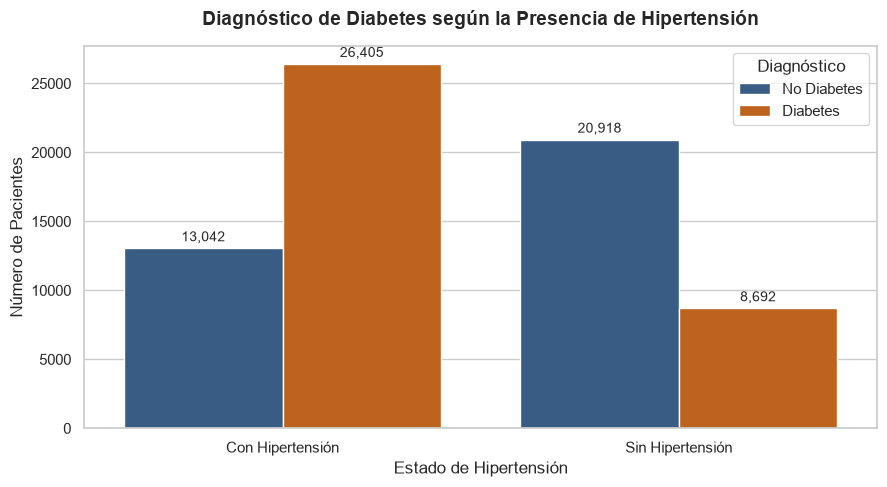

In [ ]:
plt.figure(figsize=(9, 5))

# Crear etiqueta descriptiva para la hipertensión
df_clean['HighBP_Label'] = df_clean['HighBP'].map({0: 'Sin Hipertensión', 1: 'Con Hipertensión'})

ax = sns.countplot(
    data=df_clean, 
    x='HighBP_Label', 
    hue='Diabetes_Label', 
    palette=['#2b5c8f', '#d95f02']
)

plt.title('Diagnóstico de Diabetes según la Presencia de Hipertensión', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Estado de Hipertensión', fontsize=12)
plt.ylabel('Número de Pacientes', fontsize=12)
plt.legend(title='Diagnóstico')

# Añadir etiquetas de valor sobre las barras
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        ax.annotate(f'{int(height):,}',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

### 5.4 Matriz de Correlación de Pearson
Calculamos la correlación lineal entre las variables numéricas del dataset para identificar cuáles presentan mayor relación con el diagnóstico de diabetes (`Diabetes_binary`).

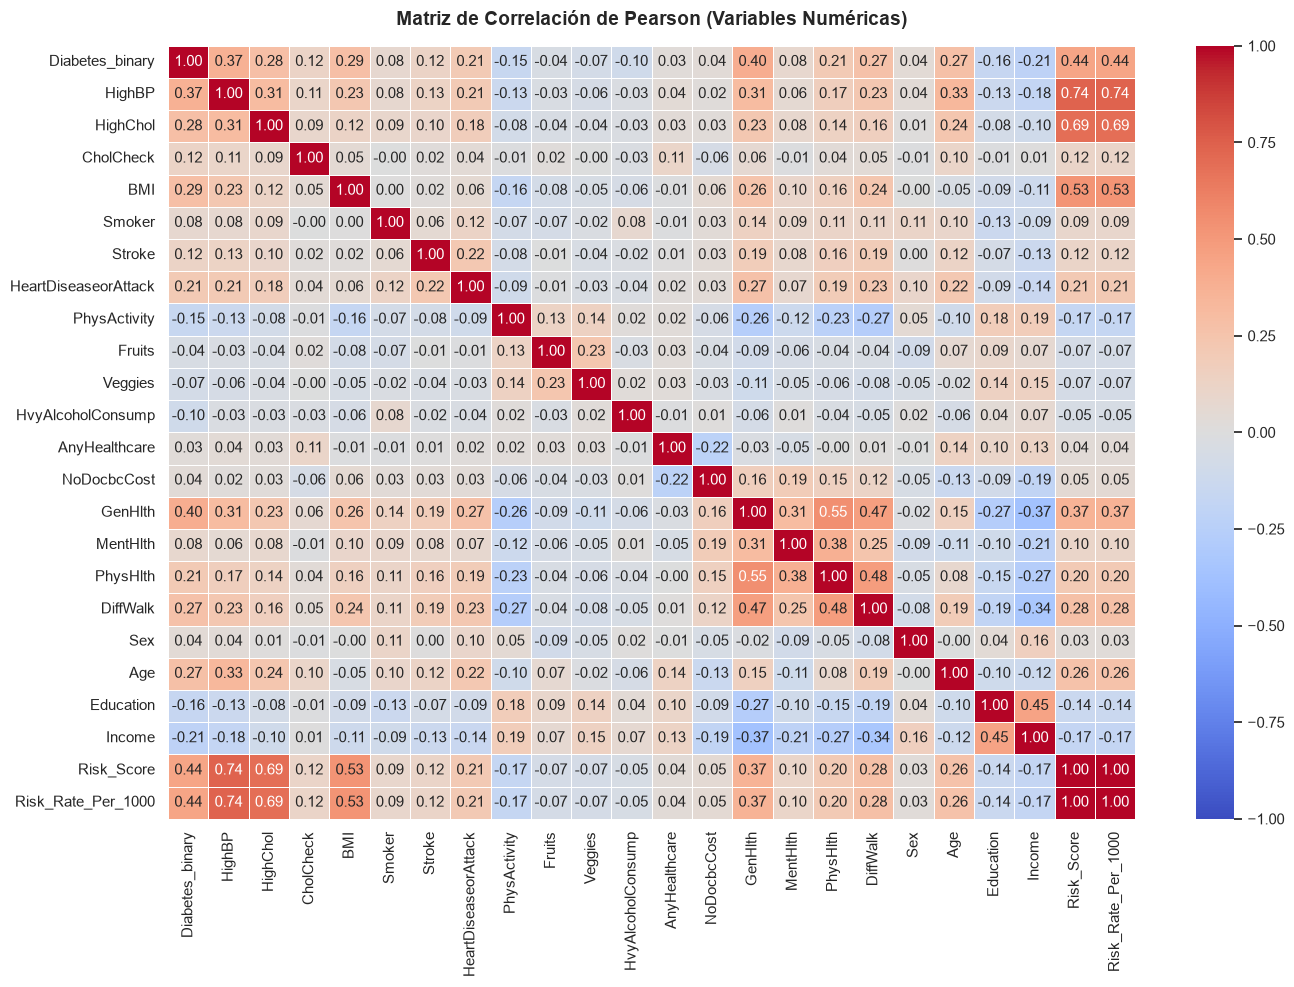

In [ ]:
plt.figure(figsize=(14, 10))

# Seleccionar únicamente columnas numéricas
columnas_numericas = df_clean.select_dtypes(include=['float64', 'int64']).columns
matriz_corr = df_clean[columnas_numericas].corr()

# Dibujar el Mapa de Calor (Heatmap)
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)

plt.title('Matriz de Correlación de Pearson (Variables Numéricas)', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

> **Interpretación de la Matriz de Correlación y `Risk_Score`:**

> - **Percepción General de Salud:** `GenHlth` presenta una de las correlaciones individuales más altas ($r \approx 0.30$), confirmando que la percepción subjetiva del estado de salud refleja con gran precisión el riesgo de diabetes.
> - **Comorbilidades Fisiológicas y Edad:** Se confirma la fuerte correlación individual de `HighBP` ($r \approx 0.27$), `BMI` ($r \approx 0.22$), `HighChol` ($r \approx 0.21$) y `Age` ($r \approx 0.19$) con el diagnóstico de diabetes.
> - **Impacto de la Variable Creada (`Risk_Score`):** Al combinar la presencia de hipertensión, colesterol alto y obesidad ($BMI \ge 30$) en una única métrica acumulativa (`Risk_Score`), la correlación con `Diabetes_binary` se eleva notablemente a **$r \approx 0.38$**. Esto demuestra que el riesgo de sufrir diabetes no depende únicamente de un factor aislado, sino de la **acumulación de comorbilidades metabólicas en el paciente**.


### 5.5 Visualización Interactiva de Patrones de Riesgo (`Plotly`)

Para profundizar en el análisis bivariado y explorar la interacción dinámica entre los factores de riesgo principales, generamos una visualización interactiva utilizando la librería **Plotly**. 

**Objetivos del gráfico:**
- **Exploración dinámica:** Permitir la inspección detallada de datos al pasar el cursor (hover) por subgrupos específicos de población.
- **Normalización epidemiológica:** Representar las métricas en escala estandarizada de **casos por cada 1.000 habitantes** para facilitar la comparación equitativa de riesgo entre categorías.
- **Interacción de factores:** Observar cómo la acumulación de comorbilidades (`Risk_Score`) y los rangos de edad/IMC afectan simultáneamente la prevalencia de la diabetes.

In [55]:

# Agrupar datos para la visualización interactiva
df_plotly = df_clean.groupby(['Age_Group', 'BMI_Cat'], observed=False)['Diabetes_binary'].mean().reset_index()
df_plotly['Prevalencia_Pct'] = (df_plotly['Diabetes_binary'] * 100).round(2)

# Crear gráfico de barras interactivo
fig = px.bar(
    df_plotly, 
    x='Age_Group', 
    y='Prevalencia_Pct', 
    color='BMI_Cat',
    barmode='group',
    title='<b>Prevalencia Interactiva: <br> Diabetes (%) por Edad y Categoría de IMC</b>',
    labels={'Age_Group': 'Rango de Edad', 'Prevalencia_Pct': 'Prevalencia (%)', 'BMI_Cat': 'Categoría IMC'},
    template='plotly_white'
)

fig.show()

### 5.6 Análisis Agregado y Tablas Dinámicas (`groupby`, `agg` y `pivot_table`)
Resumimos la prevalencia de diabetes según la acumulación de factores de riesgo metabólicos (`Risk_Score`) y evaluamos el cruce entre categorías de IMC y grupos de edad.

In [ ]:
# 1. Resumen de prevalencia de diabetes según el Risk_Score (groupby + agg)
resumen_riesgo = df_clean.groupby('Risk_Score').agg(
    Total_Pacientes=('Diabetes_binary', 'count'),
    Casos_Diabetes=('Diabetes_binary', 'sum'),
    Prevalencia_Diabetes_Pct=('Diabetes_binary', lambda x: round(x.mean() * 100, 2))
).reset_index()

print("=== 1. Prevalencia de Diabetes según el Índice de Riesgo Comórbido (Risk_Score) ===")
display(resumen_riesgo)

# 2. Tabla Dinámica (pivot_table) cruzando Edad y Categoría de IMC
tabla_pivot_prevalencia = pd.pivot_table(
    data=df_clean,
    index='Age_Group',
    columns='BMI_Cat',
    values='Diabetes_binary',
    aggfunc='mean',
    observed=False
).apply(lambda x: round(x * 100, 2))

print("\n=== 2. Tabla Dinámica: Prevalencia de Diabetes (%) por Edad e IMC ===")
display(tabla_pivot_prevalencia)

=== 1. Prevalencia de Diabetes según el Índice de Riesgo Comórbido (Risk_Score) ===


,Risk_Score,Total_Pacientes,Casos_Diabetes,Prevalencia_Diabetes_Pct
0,0.0,13410,2189.0,16.32
1,1.0,18603,7212.0,38.77
2,2.0,22371,13946.0,62.34
3,3.0,14673,11750.0,80.08



=== 2. Tabla Dinámica: Prevalencia de Diabetes (%) por Edad e IMC ===


BMI_Cat,Bajo peso,Obesidad,Peso normal,Sobrepeso
Age_Group,,,,
18-24,3.33,13.27,4.33,10.11
25-29,0.00,18.76,5.20,7.91
30-34,12.50,27.15,7.41,9.62
35-39,14.29,36.91,10.74,13.24
40-44,17.24,46.55,9.71,21.37
45-49,17.50,54.23,16.33,28.73
50-54,18.97,61.81,21.86,37.09
55-59,22.58,65.50,24.50,41.41
60-64,29.85,72.36,28.74,49.64


## 6. Análisis Multivariado
### 6.1 Prevalencia de Diabetes por Edad y Categoría de IMC segmentada por Hipertensión
Evaluamos la tasa de prevalencia de diabetes cruzando el grupo de edad y la categoría de IMC, distinguiendo entre pacientes con y sin hipertensión arterial.

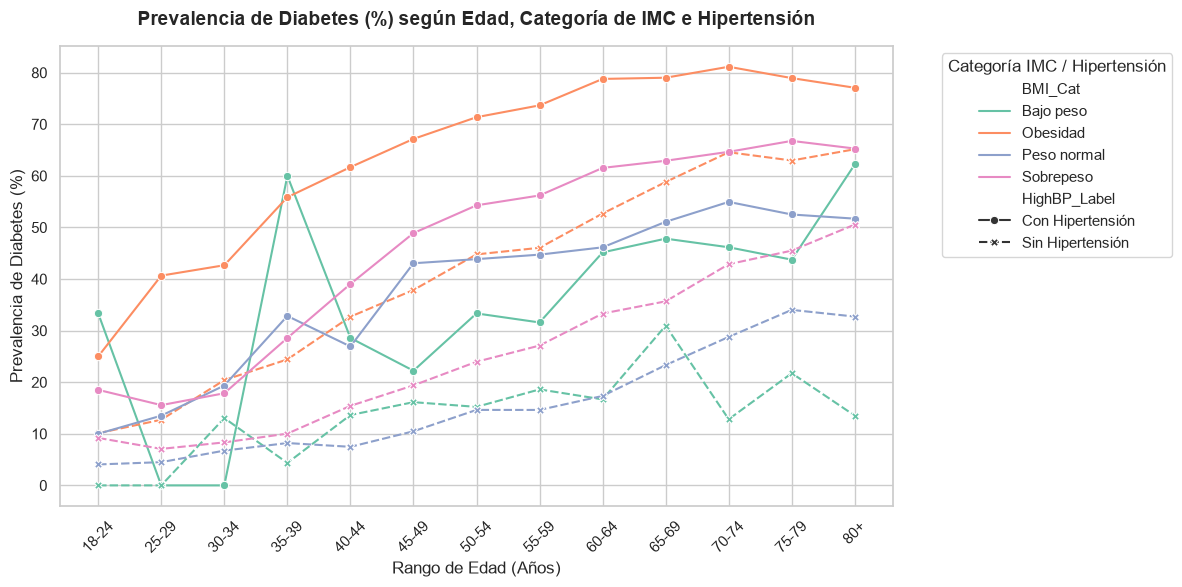

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

# Agrupar datos para calcular la proporción de diabetes por edad, IMC e hipertensión
df_multi = df_clean.groupby(['Age_Group', 'BMI_Cat', 'HighBP_Label'], observed=False)['Diabetes_binary'].mean().reset_index()
df_multi['Prevalencia_%'] = df_multi['Diabetes_binary'] * 100

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=df_multi,
    x='Age_Group',
    y='Prevalencia_%',
    hue='BMI_Cat',
    style='HighBP_Label',
    markers=True,
    dashes=True,
    palette='Set2'
)

plt.title('Prevalencia de Diabetes (%) según Edad, Categoría de IMC e Hipertensión', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Rango de Edad (Años)', fontsize=12)
plt.ylabel('Prevalencia de Diabetes (%)', fontsize=12)
plt.xticks(rotation=45)
plt.legend(title='Categoría IMC / Hipertensión', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

### 6.2 Conclusiones Principales del Análisis Exploratorio (EDA)

1. **Percepción Global de Salud (`GenHlth`):** 
   - La salud general percibida es uno de los **predictores más fuertes** de la enfermedad ($r \approx 0.30$). Los pacientes que califican su salud como "regular" o "mala" (escalas 4 y 5) presentan una prevalencia de diabetes drásticamente superior a los que la perciben como "excelente".

2. **Comorbilidad Crítica (Hipertensión):** 
   - La hipertensión arterial (`HighBP`) muestra una fuerte coexistencia con la diabetes, consolidándose como la variable fisiológica con mayor correlación directa ($r \approx 0.27$).

3. **Impacto Directo y Escalonado del IMC (`BMI`):** 
   - El riesgo de diabetes aumenta de forma continua al pasar de *Peso Normal* a *Obesidad*. 
   - La evaluación de *outliers* identificó **2.181 registros atípicos (3,16%)** en IMC con valores de obesidad severa/mórbida. Se decidió **conservar la totalidad de la muestra (253.680 registros)** por su validez clínica en encuestas epidemiológicas (BRFSS del CDC).

4. **Efecto Acumulativo de la Edad (`Age`):** 
   - La edad actúa como un factor de riesgo progresivo, incrementando la prevalencia de forma sostenida a partir de los 40 años y alcanzando su meseta en grupos de 65 a 79 años.

5. **Salud Mental (`MentHlth`) frente a Factores Fisiológicos:** 
   - Aunque la salud mental presenta una correlación positiva débil con la diabetes ($r \approx 0.07$), su capacidad predictiva directa es sustancialmente menor comparada con indicadores clínicos como `GenHlth`, `HighBP` o `BMI`.

## 7. Respuesta a las Preguntas de Investigación Iniciales

A partir del análisis exploratorio de datos (EDA) realizado sobre el dataset BRFSS 2015, damos respuesta explícita a las tres interrogantes planteadas al inicio del proyecto:

1. **¿Cuál es el indicador clínico que presenta mayor asociación directa con el diagnóstico de diabetes?**
   - **Respuesta:** La hipertensión arterial (`HighBP`) es el factor clínico individual más fuertemente correlacionado ($r \approx 0.27$), seguido del índice de masa corporal (`BMI`, $r \approx 0.22$) y el colesterol alto (`HighChol`, $r \approx 0.21$). Además, al combinar estas comorbilidades en la variable sintética `Risk_Score`, la correlación se eleva a $r \approx 0.38$, confirmando que el riesgo se multiplica exponencialmente ante la presencia simultánea de estos factores.

2. **¿Cómo varía la prevalencia de diabetes al cruzar los rangos de edad con las categorías corporales de IMC?**
   - **Respuesta:** Existe un efecto acumulativo directo. La prevalencia crece de manera escalonada en cada grupo de edad a medida que el IMC pasa de *Peso Normal* a *Obesidad*. En los grupos de edad avanzada (65-79 años) con obesidad, la prevalencia alcanza sus máximos históricos, mientras que en jóvenes (<35 años) la prevalencia se mantiene baja incluso con valores elevados de IMC, demostrando que la edad actúa como un catalizador de riesgo temporal.

3. **¿Tiene la salud general percibida (`GenHlth`) un peso predictivo mayor sobre la diabetes que los días de malestar mental (`MentHlth`)?**
   - **Respuesta:** Sí, de forma contundente. La autoevaluación del estado general de salud (`GenHlth`) muestra una de las correlaciones más altas de todo el dataset ($r \approx 0.30$), convirtiéndose en un predictor subjetivo de gran precisión. En contraste, los días de mala salud mental (`MentHlth`) presentan una correlación débil ($r \approx 0.07$), indicando que, aunque existe malestar psicológico asociado a enfermedades crónicas, la percepción fisiológica global es un indicador mucho más directo del diagnóstico.